In [ ]:
# Empty cell required for the "ruff" extension

# Feature model analysis

Feature models are techniques to extract information from data (in this case, a string).
In the context of near-duplicates detection feature models are used by the Simhash algorithm to create fixed-length fingerprints.
Therefore, it's crucial to find the optimal feature model (and its parameters).
In this project, 4 feature models are considered: bag_of_words, shingles, tf-idf and embeddings.

## bag_of_words

The simplest feature model of the four. For a given string, its features are the words it's made of.
Example: "This is a string" -> ("This", "is", "a", "string")
Hence, two strings are "near-equal" iff they contain about the same words, in any order.

It's simple and quick, but cannot detect locality.
Example: "The bank is after the office" is exactly equal to "The office is after the bank"

## shingles

Strings are sliced using a sliding window algorithm, with a certain _window_size_.
Example: "This is a string" -> ("Thi", "his", " is", "is ", ...) with _window_size_=3
As before, two strings are "near-equal" iff they contain about the same shingles, in any order.

Compared to _bag_of_words_, it generates many more elements but it can detect locality (to some degree).
As a middle-ground, the "word-based" shingle feature model is also considered here: it iterates over words, instead of characters.
Example: "This is a string" -> ("This is", "is a", "a string") with _window_size_=2

## tf-idf

A more refined version of _bag_of_words_, which values "rare" words more than "common" ones.
Each word in each string has a weight (0,1).

## embeddings

Generated using the transformer-based model Qwen3-embedding:0.6b.
Two strings are "near-equal" semantically if their embedding is similar.
Despite its great performance, it tends to be computationally more expensive than other models.


In [ ]:
import itertools
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import pyspark.sql.functions as F
import seaborn as sns
from pyspark.sql import DataFrame
from tqdm import tqdm

sys.path.append(str(Path.cwd().parent))

from src.config import FEATURE_MODELS, FINGERPRINT_SIZES
from src.datasets import read_llm_paraphrases, read_paws, read_qqp, read_wikipedia
from src.fingerprint import ShingleParams, create_fingerprints
from src.near_duplicates import detect_near_duplicates_benchmark
from src.spark_utils import get_spark

spark = get_spark()

%load_ext autoreload
%autoreload 2

/opt/homebrew/anaconda3/envs/pyspark-dev/lib/python3.14/site-packages/pyspark/sql/pandas/functions.py:777: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/opt/homebrew/anaconda3/envs/pyspark-dev/lib/python3.14/site-packages/pyspark/sql/pandas/typehints.py:60: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/opt/homebrew/anaconda3/envs/pyspark-dev/lib/python3.14/site-packages/pyspark/sql/pandas/functions.py:777: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/opt/homebrew/anaconda3/envs/pyspark-dev/lib/python3.14/site-packages/pyspark/sql/pandas/typehints.py:60: FutureW

In [ ]:
DATASETS = ("wikipedia", "paws", "llm-paraphrases", "qqp")
FEATURE_MODELS = ["bag_of_words", "embeddings", "tf-idf", "shingles"]
F_SIZES = [32, 64, 128, 256, 512]
SHINGLE_CONFIGS = [
    ShingleParams(shingle_size=3, over_words=False),
    ShingleParams(shingle_size=5, over_words=False),
    ShingleParams(shingle_size=7, over_words=False),
    ShingleParams(shingle_size=3, over_words=True),
    ShingleParams(shingle_size=5, over_words=True),
    ShingleParams(shingle_size=7, over_words=True),
]

### CONFIGURABLE PARAMS ###
DATASET_NAME = "wikipedia"
COMPUTE = False
SAMPLE = True
K_SAMPLES = 10
K_CHOSEN = None  # [1, 2, 3]
SAMPLE_RATIO = 0.0005
### END CONFIGURABLE PARAMS ###

assert [fs in FINGERPRINT_SIZES for fs in F_SIZES]
assert DATASET_NAME in DATASETS
assert K_SAMPLES > 0 and K_SAMPLES < min(F_SIZES)

COL_IN1 = "data1"
COL_IN2 = "data2"
COL_OUT1 = "fingerprint1"
COL_OUT2 = "fingerprint2"
TRUTH_COL = "is_near_duplicate"

dataset: DataFrame | None = None
match DATASET_NAME:
    case "paws":
        dataset = read_paws()
    case "wikipedia":
        dataset = read_wikipedia(variant="10percent")
    case "llm-paraphrases":
        dataset = read_llm_paraphrases()
    case "qqp":
        dataset = read_qqp()

if SAMPLE:
    dataset = dataset.sample(SAMPLE_RATIO)

# Data Cleanup
clean_expr = lambda col_name: F.trim(
    F.regexp_replace(F.lower(F.col(col_name)), r"[\n\r\t]|[^a-z\s]", "")
)

dataset = dataset.filter(F.col(COL_IN1).isNotNull() & F.col(COL_IN2).isNotNull())
dataset = (
    dataset.withColumn(f"{COL_IN1}_cleaned", clean_expr(COL_IN1))
    .withColumn(f"{COL_IN2}_cleaned", clean_expr(COL_IN2))
    .filter((F.col(f"{COL_IN1}_cleaned") != "") & (F.col(f"{COL_IN2}_cleaned") != ""))
)

dataset.persist()
dataset_sample_size = dataset.count()
sample_near_dup_count = dataset.filter(F.col("is_near_duplicate") == True).count()
print(f"Selected dataset: {DATASET_NAME}, {dataset_sample_size} rows.")
print(f"This sample has {sample_near_dup_count} near-duplicate rows.")


def feature_model_benchmark():
    models = FEATURE_MODELS
    fingerprint_sizes = F_SIZES
    experiments = []
    results = []

    for m, fs in itertools.product(models, fingerprint_sizes):
        if m == "shingles":
            for conf in SHINGLE_CONFIGS:
                experiments.append({"model": m, "fingerprint_size": fs, "other": conf})
        else:
            experiments.append({"model": m, "fingerprint_size": fs, "other": None})

    for exp in tqdm(experiments, desc="Feature model benchmark running..."):
        df_exp = create_fingerprints(
            df=dataset,
            model=exp["model"],
            input_col=f"{COL_IN1}_cleaned",
            output_col=COL_OUT1,
            fingerprint_size=exp["fingerprint_size"],
            other=exp["other"],
        )
        df_exp = create_fingerprints(
            df=df_exp,
            model=exp["model"],
            input_col=f"{COL_IN2}_cleaned",
            output_col=COL_OUT2,
            fingerprint_size=exp["fingerprint_size"],
            other=exp["other"],
        )

        df_exp.write.format("noop").mode("overwrite").save()
        df_exp.persist()

        if K_CHOSEN is not None:
            Ks = K_CHOSEN
        else:
            Ks = [
                round(i * (exp["fingerprint_size"] // 2) / K_SAMPLES)
                for i in range(1, K_SAMPLES + 1)
            ]

        for K in Ks:
            if K <= int(exp["fingerprint_size"] / 2):
                metrics = detect_near_duplicates_benchmark(
                    df=df_exp, f1_col=COL_OUT1, f2_col=COL_OUT2, truth_col=TRUTH_COL, K=K
                )
                row = {**exp, "K": K, **metrics.__dict__}
                results.append(row)

        df_exp.unpersist()

    return pd.DataFrame(results)

Selected dataset: wikipedia, 0 rows.
This sample has 0 near-duplicate rows.


In [6]:
benchmark_df = pd.DataFrame()
filename = f"results/{DATASET_NAME}/feature_benchmark_{DATASET_NAME}.csv"
csv_file = Path(filename)
if csv_file.is_file() and not COMPUTE:
    benchmark_df = pd.read_csv(filename)
else:
    benchmark_df = feature_model_benchmark()
    # benchmark_df.to_csv(filename)
benchmark_df

,Unnamed: 0,model,fingerprint_size,other,K,accuracy,precision,recall,f1_score
0,0,tf-idf,64,NaN,0,0.837675,1.000000,0.676,0.806683
1,1,tf-idf,64,NaN,3,0.938878,1.000000,0.878,0.935037
2,2,tf-idf,64,NaN,6,0.985972,1.000000,0.972,0.985801
3,3,tf-idf,64,NaN,9,0.995992,0.997992,0.994,0.995992
4,4,tf-idf,64,NaN,12,0.996994,0.997996,0.996,0.996997
5,5,tf-idf,64,NaN,15,0.997996,0.998000,0.998,0.998000
6,6,tf-idf,64,NaN,18,0.997996,0.996016,1.000,0.998004
7,7,tf-idf,64,NaN,21,0.995992,0.992063,1.000,0.996016
8,8,tf-idf,64,NaN,24,0.985972,0.972763,1.000,0.986193
9,9,tf-idf,64,NaN,27,0.944890,0.900901,1.000,0.947867


In [ ]:
# Max f1 score for fingerprint size
assert benchmark_df is not None
top_fs_f1 = (
    benchmark_df.sort_values(by=["fingerprint_size"])[["fingerprint_size", "f1_score"]]
    .groupby(by=["fingerprint_size"])
    .agg({"f1_score": "max"})
)
top_fs_f1["f1_score"] = top_fs_f1["f1_score"].round(2)
plt.figure(figsize=(10, 6))
plot = sns.barplot(
    data=top_fs_f1, x="fingerprint_size", y="f1_score", hue="f1_score", palette="deep"
)
plt.ylim(top_fs_f1["f1_score"].min() - 0.2, 1)
plt.title("Max f1_score for each fingerprint size")
plt.legend(title="Legend", loc="upper left", bbox_to_anchor=(1.02, 1))
plt.show()

In [ ]:
# Best f1 score for each model
assert benchmark_df is not None
top_model = (
    benchmark_df.sort_values(by=["f1_score"])[["model", "f1_score"]]
    .groupby(by=["model"])
    .agg({"f1_score": "max"})
)
top_model["f1_score"] = top_model["f1_score"].round(2)
plt.figure(figsize=(10, 6))
plot = sns.barplot(data=top_model, x="model", y="f1_score", hue="f1_score", palette="deep")
plt.ylim(top_model["f1_score"].min() - 0.2, 1)
plt.title("Best f1_score for each model")
plt.legend(title="Legend", loc="upper left", bbox_to_anchor=(1.02, 1))
plt.show()

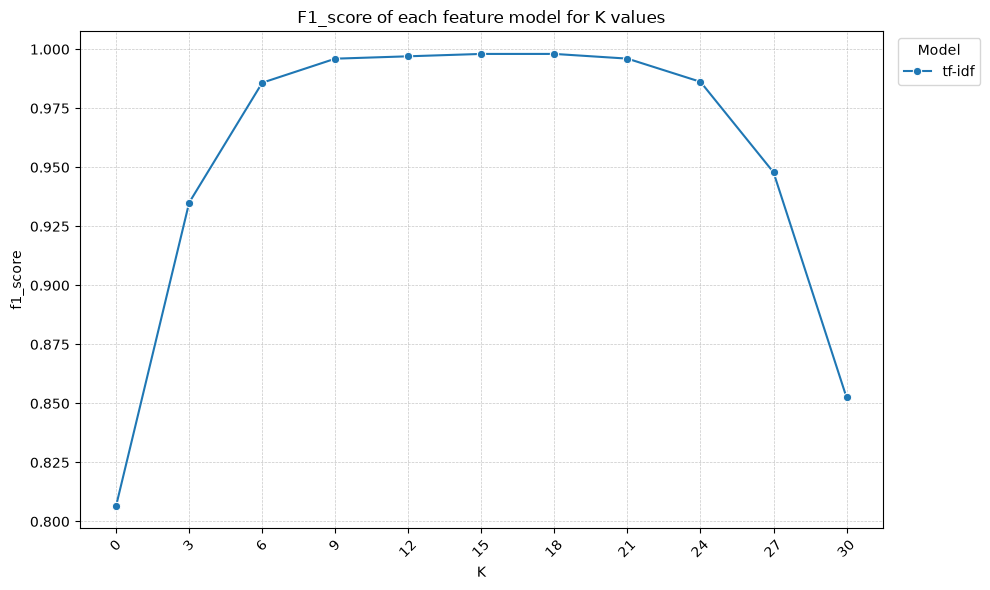

In [ ]:
# Lineplot K - f1_score
assert benchmark_df is not None

plt.figure(figsize=(10, 6))

stats_df = benchmark_df.loc[benchmark_df["fingerprint_size"] == 64]
stats_df = stats_df.loc[stats_df.groupby(["model", "K"])["f1_score"].idxmax()]

plot = sns.lineplot(
    data=stats_df, x="K", y="f1_score", hue="model", style="model", markers=True, errorbar=None
)

unique_k = sorted(stats_df["K"].unique())
plt.xticks(ticks=unique_k, labels=[str(el) for el in unique_k], rotation=45)

plt.grid(True, which="both", linestyle="--", linewidth=0.5, alpha=0.7)
plt.legend(title="Model", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.title("F1_score of each feature model for K values")
plt.tight_layout()

plt.show()

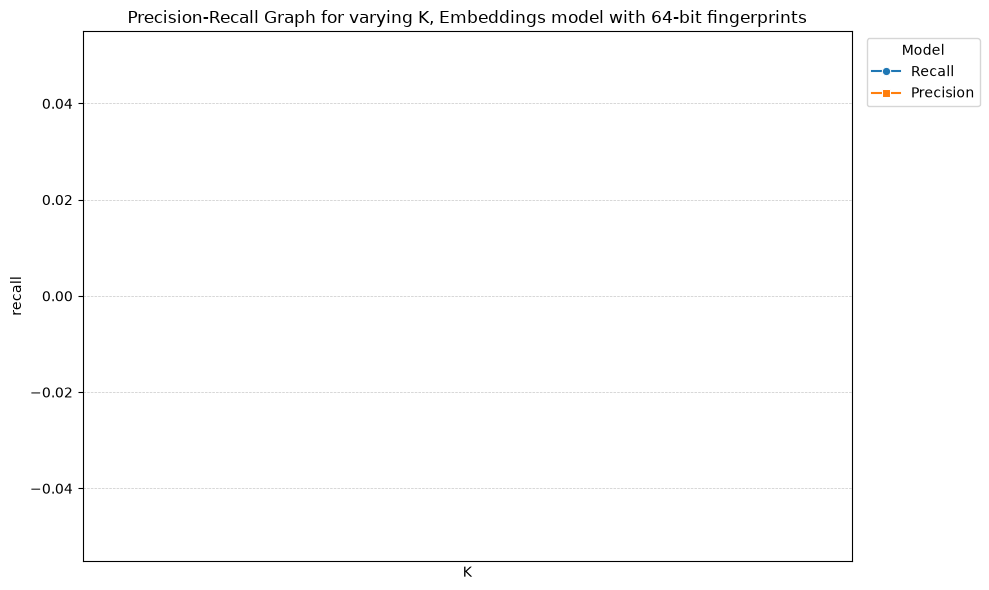

In [7]:
# Lineplot K - f1_score
assert benchmark_df is not None

plt.figure(figsize=(10, 6))

stats_df = benchmark_df.loc[benchmark_df["fingerprint_size"] == 64]
stats_df = stats_df.loc[benchmark_df["model"] == "embeddings"]

sns.lineplot(
    data=stats_df,
    x="K",
    y="recall",
    marker="o",
    label="Recall",
    errorbar=None,
)

sns.lineplot(
    data=stats_df,
    x="K",
    y="precision",
    marker="s",
    label="Precision",
    errorbar=None,
)

unique_k = sorted(stats_df["K"].unique())
plt.xticks(ticks=unique_k, labels=[str(el) for el in unique_k], rotation=45)

plt.grid(True, which="both", linestyle="--", linewidth=0.5, alpha=0.7)
plt.legend(title="Model", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.title("Precision-Recall Graph for varying K, Embeddings model with 64-bit fingerprints")
plt.tight_layout()

plt.show()

In [ ]:
# F1 score heatmap by feature model / fingerprint_size
assert benchmark_df is not None
plot_df = benchmark_df.pivot_table(
    index="model", columns="fingerprint_size", values="f1_score", aggfunc="max"
).round(2)
plt.figure(figsize=(10, 6))
plot = sns.heatmap(data=plot_df, annot=True, cmap="coolwarm", cbar=True)
plt.title("F1_score by feature model / fingerprint size")
plt.xlabel("Fingerprint size")
plt.ylabel("Feature model")
plt.show()

In [ ]:
# F1_score by shingle size / shingle method (only "shingles" feature model)
assert benchmark_df is not None
plot_df = pd.DataFrame()
plot_df[["shingle_size", "over_words"]] = (
    benchmark_df["other"].dropna().str.extract(r"shingle_size=(\d+).*?over_words=(True|False)")
)
plot_df["f1_score"] = benchmark_df[["other", "f1_score"]].dropna()["f1_score"]
plot_df["shingle_size"] = plot_df["shingle_size"].astype(int)
plot_df["over_words"] = plot_df["over_words"].map({"True": "words", "False": "chars"})
plot_df = plot_df.pivot_table(
    index="shingle_size", columns="over_words", values="f1_score", aggfunc="max"
).round(2)
plt.figure(figsize=(10, 6))
plot = sns.heatmap(data=plot_df, annot=True, cmap="coolwarm", cbar=True)
plt.title("F1_score by shingle size / shingle method")
plt.xlabel("Shingle method")
plt.ylabel("Shingle size")
plt.show()

In [ ]:
assert dataset is not None
dataset.unpersist()
spark.stop()